In [55]:
import os
import sys
os.environ['CUDA_VISIBLE_DEVICES'] = 'MIG-f80e9374-504a-571b-bac0-6fb00750db4c'
#sys.path.insert(0,'/users/kobbad/feat_leakage/deepSEA_negatives')
sys.path.insert(0,'/users/kobbad/feat_leakage/all_ap1_motifs')
from model import Beluga
import torch
from ism_function import ism
import pandas as pd
from bpnetlite.io import extract_loci
from tangermeme.ersatz import dinucleotide_shuffle
from tangermeme.ersatz import substitute
import numpy as np
from matplotlib import pyplot as plt
from tangermeme.ablate import ablate
from tangermeme.marginalize import marginalize
from tangermeme.deep_lift_shap import deep_lift_shap
from tangermeme.design import greedy_substitution
import pickle
from tangermeme.predict import predict
import torch.nn
import matplotlib.pyplot as plt
from tangermeme.utils import random_one_hot
import custom_greedy
import argparse
from tqdm import tqdm
import importlib
import custom_greedy
from tangermeme.utils import characters

importlib.reload(custom_greedy)

from custom_greedy import greedy_substitution

In [2]:
results_pickle = pickle.load(open("all_results_new.pkl", "rb"))

In [71]:
score_target_2 = []
score_target_1 = []

max_len = 0

# get the max length of the scores
for r in results_pickle:
    max_len = max(max_len, len(np.array([i.item() for i in r['score_target_2']])))
    max_len = max(max_len, len(np.array([i.item() for i in r['score_target_1']])))

for r in results_pickle:
    score_2_temp = np.array([i.item() for i in r['score_target_2']])
    score_1_temp = np.array([i.item() for i in r['score_target_1']])

    # if score_2_temp is shorter than max_len, pad with the last value
    if len(score_2_temp) < max_len:
        score_2_temp = np.pad(score_2_temp, (0, max_len - len(score_2_temp)), mode='constant', constant_values=score_2_temp[-1])

    # if score_1_temp is shorter than max_len, pad with the last value
    if len(score_1_temp) < max_len:
        score_1_temp = np.pad(score_1_temp, (0, max_len - len(score_1_temp)), mode='constant', constant_values=score_1_temp[-1])

    score_target_2.append(score_2_temp)
    score_target_1.append(score_1_temp)


In [72]:
score_1 = np.array(score_target_1)
score_2 = np.array(score_target_2)

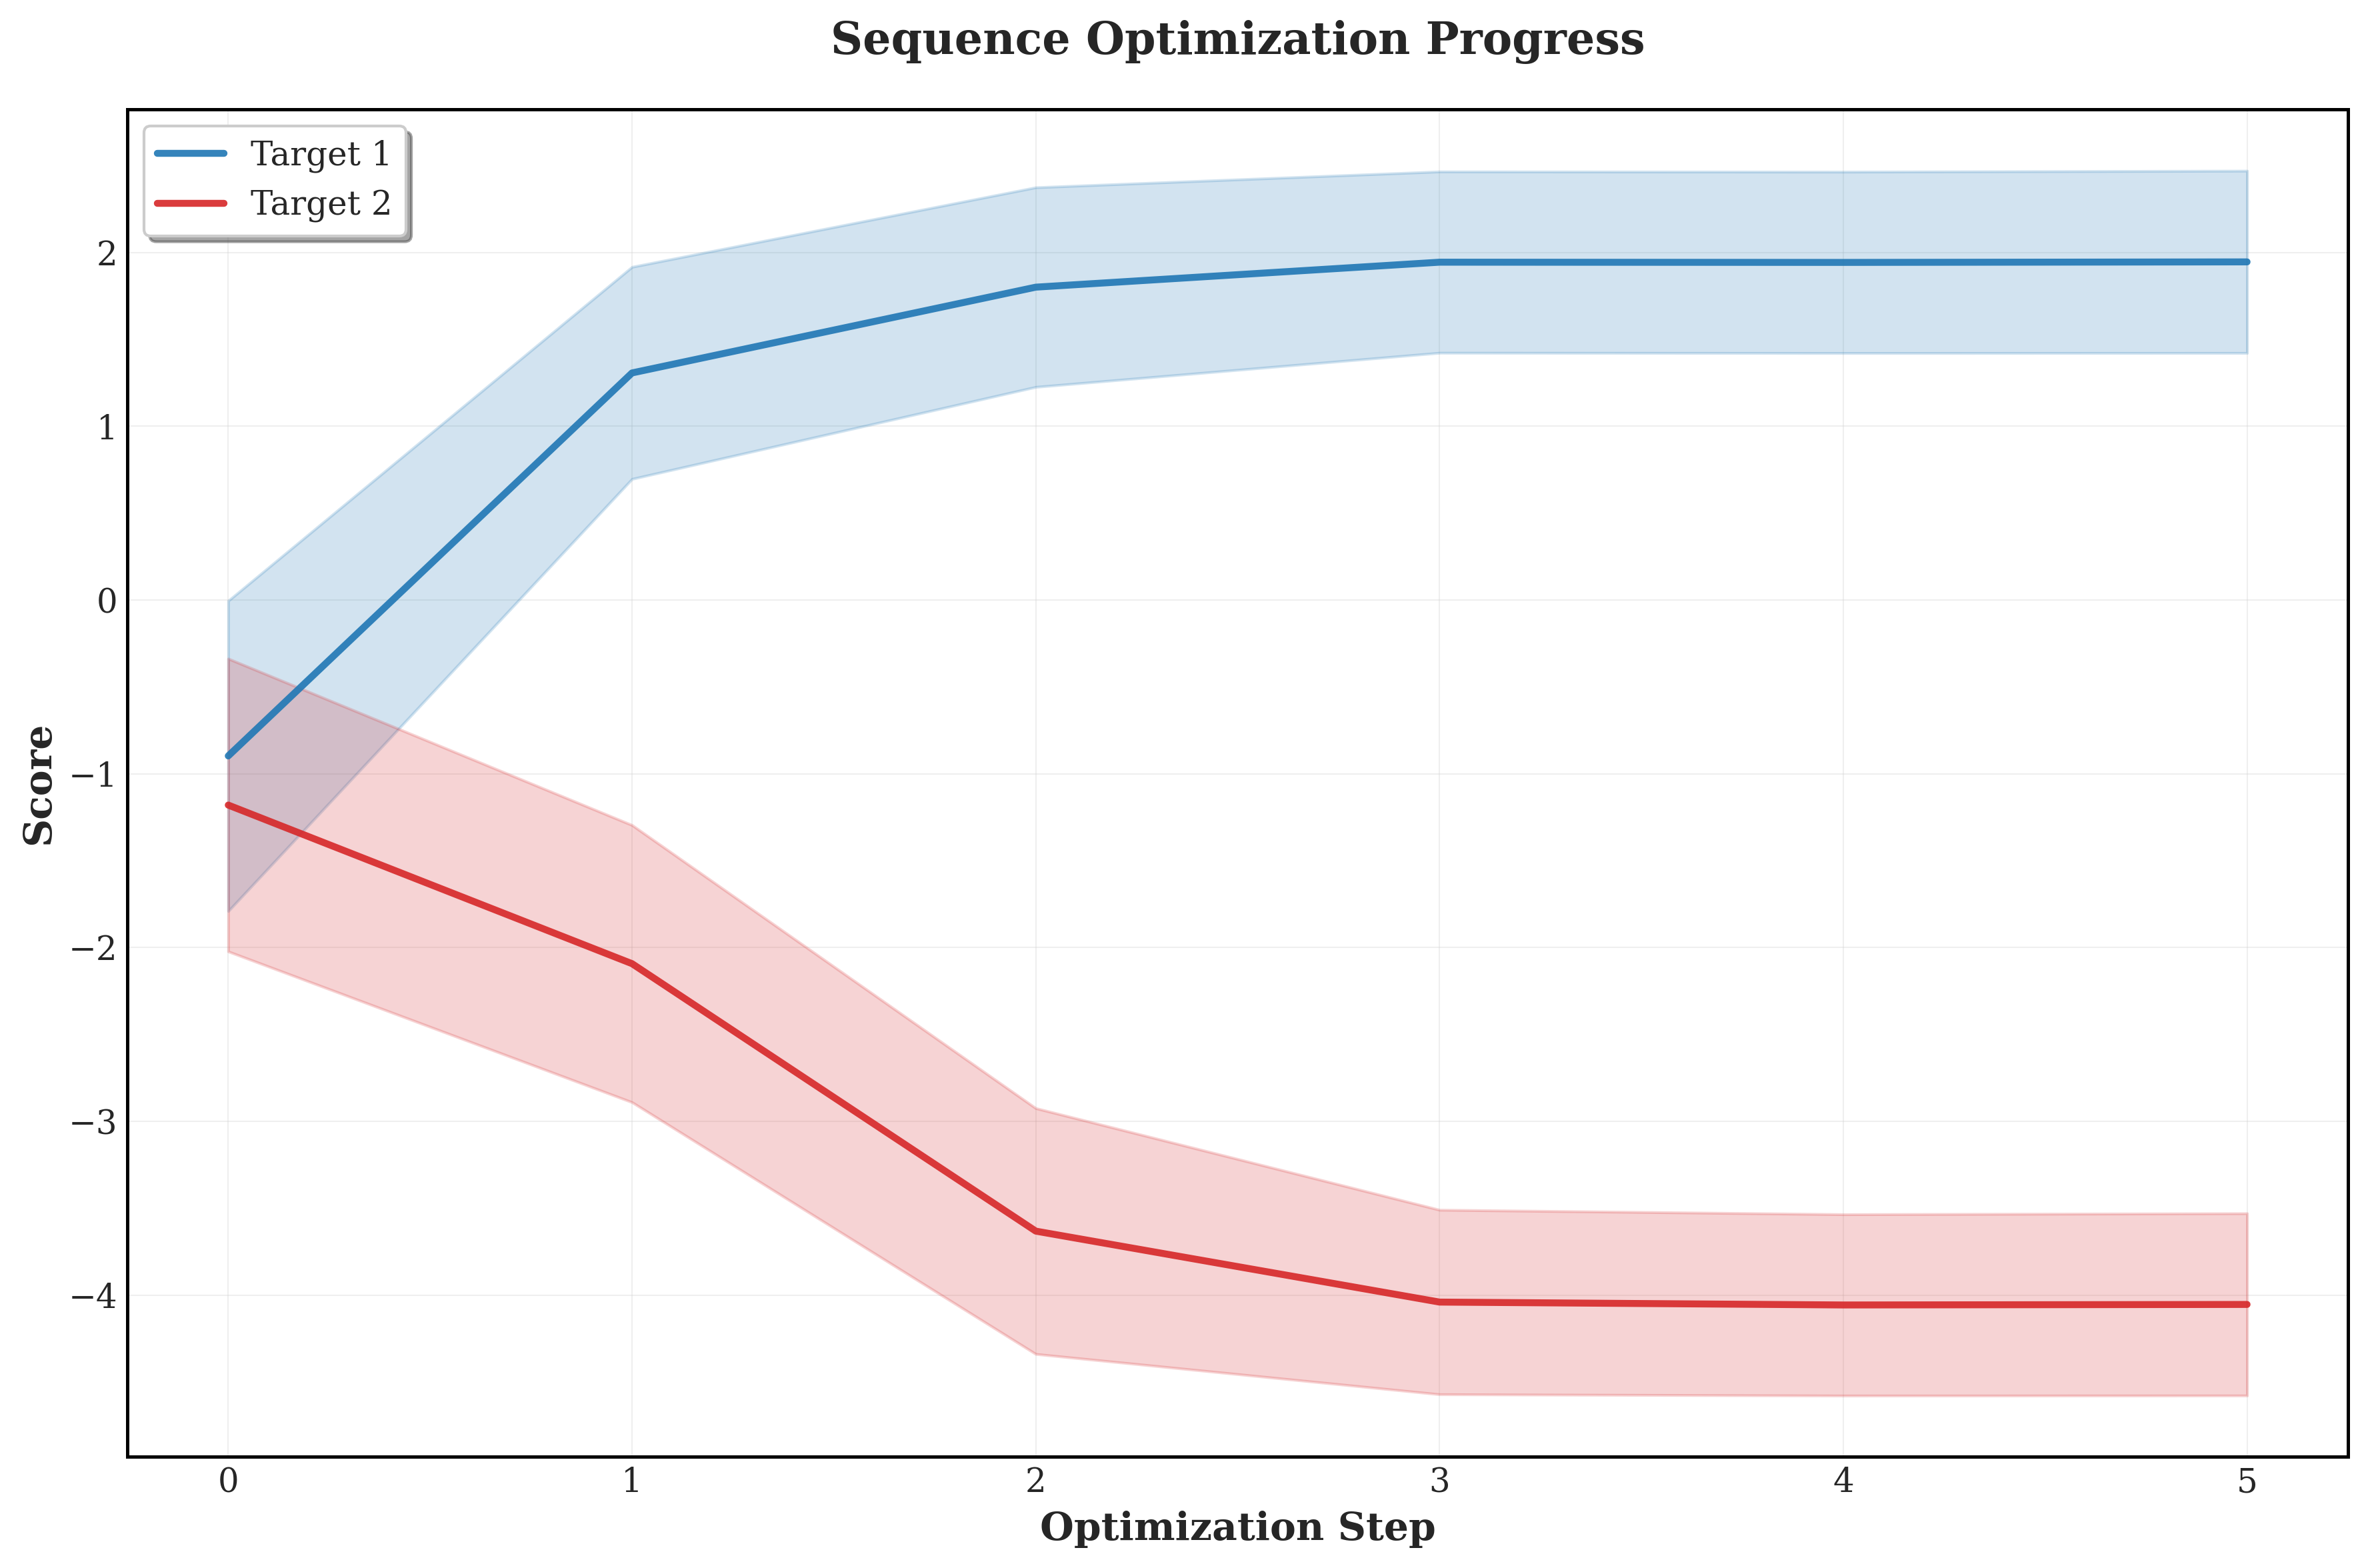

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rcParams
import seaborn as sns

# Set publication-ready style
plt.style.use('seaborn-v0_8-whitegrid')  # Clean, professional look
rcParams['font.family'] = 'DejaVu Sans'  # Use serif fonts for publication
rcParams['font.size'] = 12
rcParams['axes.labelsize'] = 14
rcParams['axes.titlesize'] = 16
rcParams['xtick.labelsize'] = 12
rcParams['ytick.labelsize'] = 12
rcParams['legend.fontsize'] = 12
rcParams['figure.titlesize'] = 16

# Convert to numpy arrays (you already have this)
score_1 = np.array(score_target_1)
score_2 = np.array(score_target_2)

# Create publication-ready plot
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)  # High DPI for crisp text

# Calculate statistics for cleaner visualization
mean_1 = np.mean(score_1, axis=0)
std_1 = np.std(score_1, axis=0)
mean_2 = np.mean(score_2, axis=0)
std_2 = np.std(score_2, axis=0)

# Create x-axis (iterations/steps)
x = np.arange(len(mean_1))

# Plot mean lines with confidence intervals
ax.plot(x, mean_1, color='#1f77b4', linewidth=2.5, label='Target 1', alpha=0.9)
ax.fill_between(x, mean_1 - std_1, mean_1 + std_1, color='#1f77b4', alpha=0.2)

ax.plot(x, mean_2, color='#d62728', linewidth=2.5, label='Target 2', alpha=0.9)
ax.fill_between(x, mean_2 - std_2, mean_2 + std_2, color='#d62728', alpha=0.2)

# Alternatively, if you want to show individual trajectories but cleaner:
# for i in range(len(score_1)):
#     ax.plot(x, score_1[i], color='#1f77b4', alpha=0.3, linewidth=0.8)
#     ax.plot(x, score_2[i], color='#d62728', alpha=0.3, linewidth=0.8)
# 
# # Plot means on top
# ax.plot(x, mean_1, color='#1f77b4', linewidth=3, label='Target 1 (mean)')
# ax.plot(x, mean_2, color='#d62728', linewidth=3, label='Target 2 (mean)')

# Customize the plot
ax.set_xlabel('Optimization Step', fontweight='bold')
ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Sequence Optimization Progress', fontweight='bold', pad=20)

# Add legend
ax.legend(loc='best', frameon=True, fancybox=True, shadow=True)

# Add grid for better readability
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Set spine properties
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)

# Adjust layout to prevent clipping
plt.tight_layout()

# Save as PDF with vector graphics (text will be searchable/selectable)
plt.savefig('sequence_optimization_scores.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Also save as high-res PNG if needed
plt.savefig('sequence_optimization_scores.png', 
            format='png', 
            dpi=300, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

plt.show()

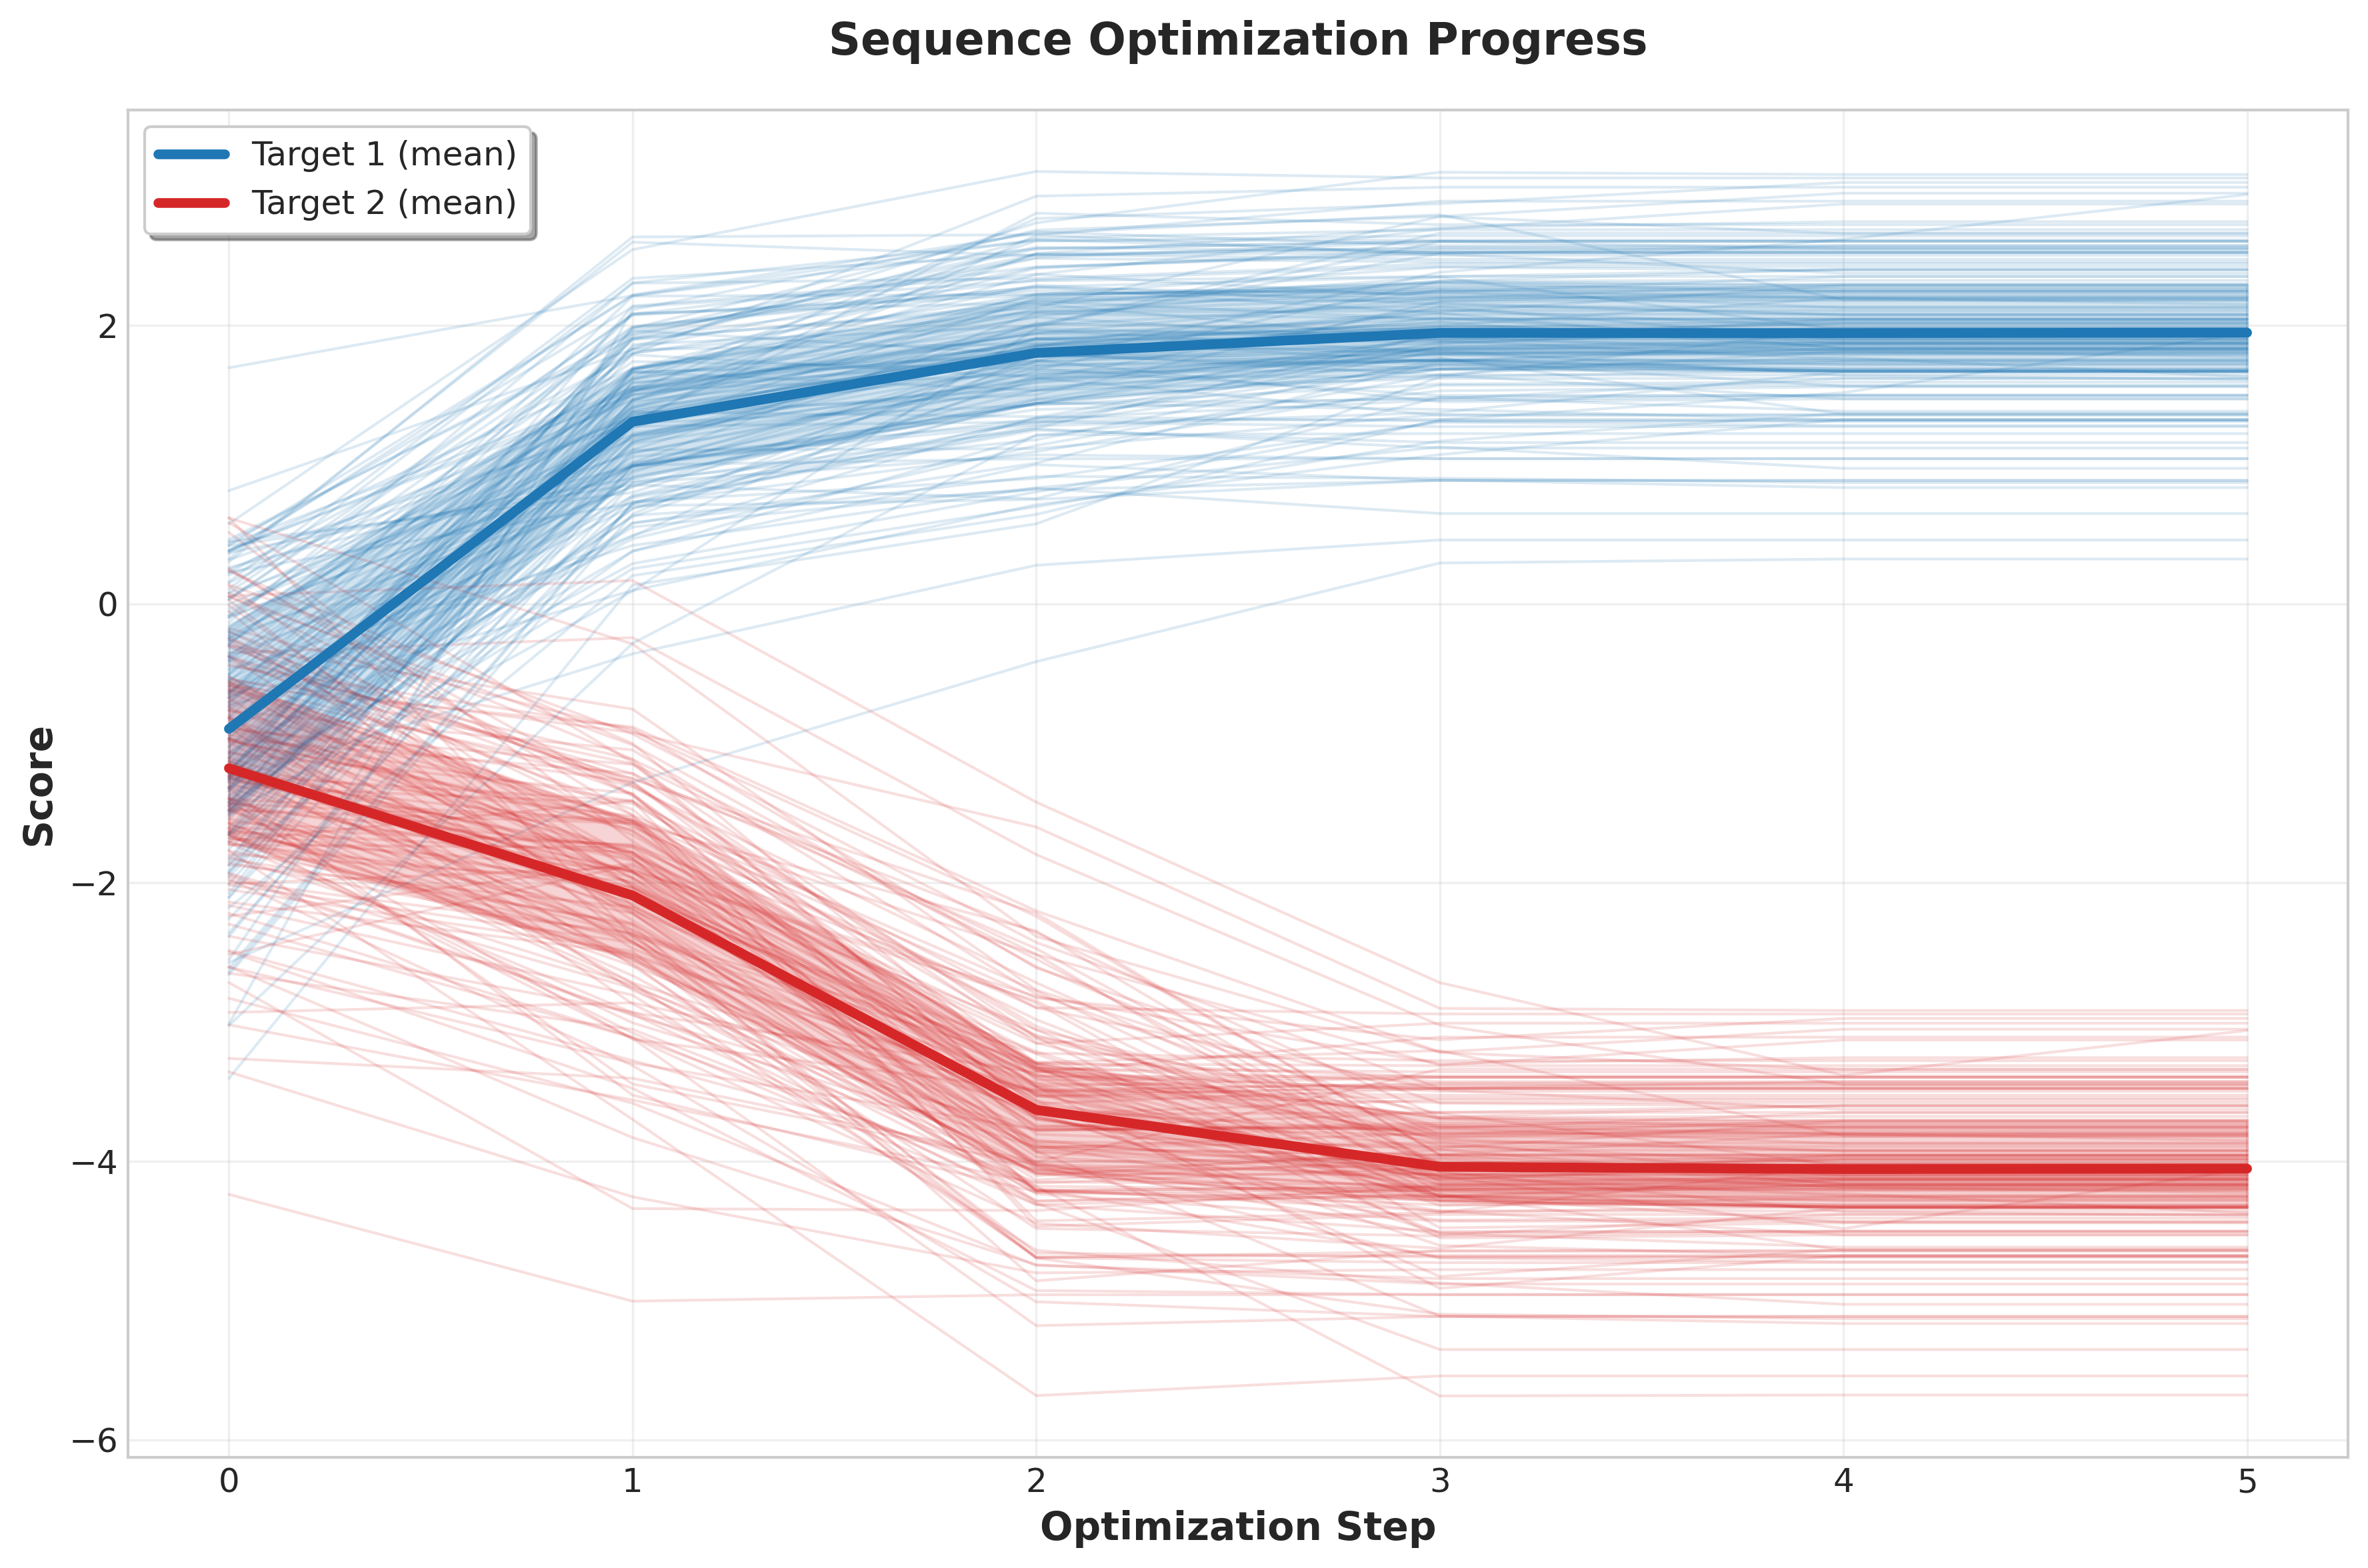

In [73]:
# Set publication-ready style
plt.style.use('seaborn-v0_8-whitegrid')  # Clean, professional look
rcParams['font.family'] = 'DejaVu Sans'  # Use serif fonts for publication
rcParams['font.size'] = 12
rcParams['axes.labelsize'] = 14
rcParams['axes.titlesize'] = 16
rcParams['xtick.labelsize'] = 12
rcParams['ytick.labelsize'] = 12
rcParams['legend.fontsize'] = 12
rcParams['figure.titlesize'] = 16
# Alternative: Show individual trajectories with better styling
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

# Plot individual trajectories with low alpha
for i in range(len(score_1)):
    ax.plot(x, score_1[i], color='#1f77b4', alpha=0.15, linewidth=1)
    ax.plot(x, score_2[i], color='#d62728', alpha=0.15, linewidth=1)

# Plot means with higher prominence
ax.plot(x, mean_1, color='#1f77b4', linewidth=3.5, label='Target 1 (mean)', zorder=10)
ax.plot(x, mean_2, color='#d62728', linewidth=3.5, label='Target 2 (mean)', zorder=10)

# Add percentile bands instead of std
p25_1, p75_1 = np.percentile(score_1, [25, 75], axis=0)
p25_2, p75_2 = np.percentile(score_2, [25, 75], axis=0)

ax.fill_between(x, p25_1, p75_1, color='#1f77b4', alpha=0.2, zorder=5)
ax.fill_between(x, p25_2, p75_2, color='#d62728', alpha=0.2, zorder=5)

# Same styling as above...
ax.set_xlabel('Optimization Step', fontweight='bold')
ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Sequence Optimization Progress', fontweight='bold', pad=20)
ax.legend(loc='best', frameon=True, fancybox=True, shadow=True)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sequence_optimization_individual.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [36]:
results_pickle[0]

{'sequence_added': ['AGACATGCCCAGACATGCCC',
  'TCACACCTTCTAAGGTGTGA',
  'ATTTATGT',
  'GTTAATCCGATTAAC'],
 'score_target_2': [array([[-1.5431004]], dtype=float32),
  array([-2.0608199], dtype=float32),
  array([-3.7715364], dtype=float32),
  array([-3.7651405], dtype=float32),
  array([-3.6516275], dtype=float32)],
 'score_target_1': [array([[-1.2521383]], dtype=float32),
  array([1.2587306], dtype=float32),
  array([2.1927], dtype=float32),
  array([2.2348282], dtype=float32),
  array([2.3483706], dtype=float32)],
 'idx_inserted': [tensor(975, device='cuda:0'),
  tensor(1029, device='cuda:0'),
  tensor(906, device='cuda:0'),
  tensor(1054, device='cuda:0')],
 'start_sequence': 'ATCATTTTCTCGATGAAAGCGTTGACCCCACATATCGTTAGTACTCTTGTACCCTATGATTGTGTAGAAACCGAACTACGGTACCTCCTGTTGGTAGTCACGATAGATTATAAAAGTATGTTCCCACCCTATCGACGAGACTGGCATCCTAGGTGTTTGCGGTGTTGGTACGTGCGCAGGTATGTAAGAGTGGTAAACGACGTGGTCAAATTAGGAATACGAATCTAGCCCTAAACCGCAACGCCTCAAATTCGCTCTAATCGAGTTGTCCCTGAACATGTTGAGTGGCCTTATAAGGTCCATAGTTCTCTG

In [39]:
motif_effects = {}

for r in results_pickle:
    score_1 = np.array([i.item() for i in r['score_target_1']])
    score_2 = np.array([i.item() for i in r['score_target_2']])
    motifs = r['motif_names_added']

    for m, motif in enumerate(motifs):
        pos_score = (score_1[m+1] - score_1[m]).item()
        neg_score = (score_2[m+1] - score_2[m]).item()

        if motif not in motif_effects:
            motif_effects[motif] = []

        motif_effects[motif].append(pos_score + neg_score)


In [ ]:
motif_effects_sum = {k: np.mean(v) for k, v in motif_effects.items()}

len(motif_effects_sum)


151

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib import rcParams

# Filter motifs that have more than one entry
filtered_motif_effects = {k: v for k, v in motif_effects.items() if len(v) > 1}

print(f"Original number of motifs: {len(motif_effects)}")
print(f"Motifs with more than one entry: {len(filtered_motif_effects)}")

# Calculate average effects and sort by average
motif_averages = {k: np.mean(v) for k, v in filtered_motif_effects.items()}
sorted_motifs = sorted(motif_averages.items(), key=lambda x: x[1], reverse=True)

# Extract sorted motif names and their corresponding data
sorted_motif_names = [item[0] for item in sorted_motifs]
sorted_motif_values = [filtered_motif_effects[motif] for motif, _ in sorted_motifs]
sorted_averages = [item[1] for item in sorted_motifs]

print(f"Top 5 motifs by average effect:")
for i in range(min(5, len(sorted_motifs))):
    motif, avg = sorted_motifs[i]
    print(f"  {motif}: {avg:.4f} (n={len(filtered_motif_effects[motif])})")

print(f"\nBottom 5 motifs by average effect:")
for i in range(max(0, len(sorted_motifs)-5), len(sorted_motifs)):
    motif, avg = sorted_motifs[i]
    print(f"  {motif}: {avg:.4f} (n={len(filtered_motif_effects[motif])})")

Original number of motifs: 151
Motifs with more than one entry: 55
Top 5 motifs by average effect:
  P53_HUMAN.H11MO.0.A: 1.1327 (n=168)
  ANDR_HUMAN.H11MO.0.A: 0.2877 (n=2)
  ZNF384_MA1125.1: 0.2753 (n=2)
  OTX1_homeodomain_1: 0.2667 (n=2)
  SMAD2_MOUSE.H11MO.0.A: 0.1530 (n=2)

Bottom 5 motifs by average effect:
  ASCL1_HUMAN.H11MO.0.A: -0.9586 (n=8)
  EOMES_TBX_2: -0.9614 (n=41)
  ZNF784_C2H2_1: -1.1510 (n=8)
  MGA_TBX_2: -1.3916 (n=84)
  RBPJ_MA1116.1: -1.6321 (n=2)


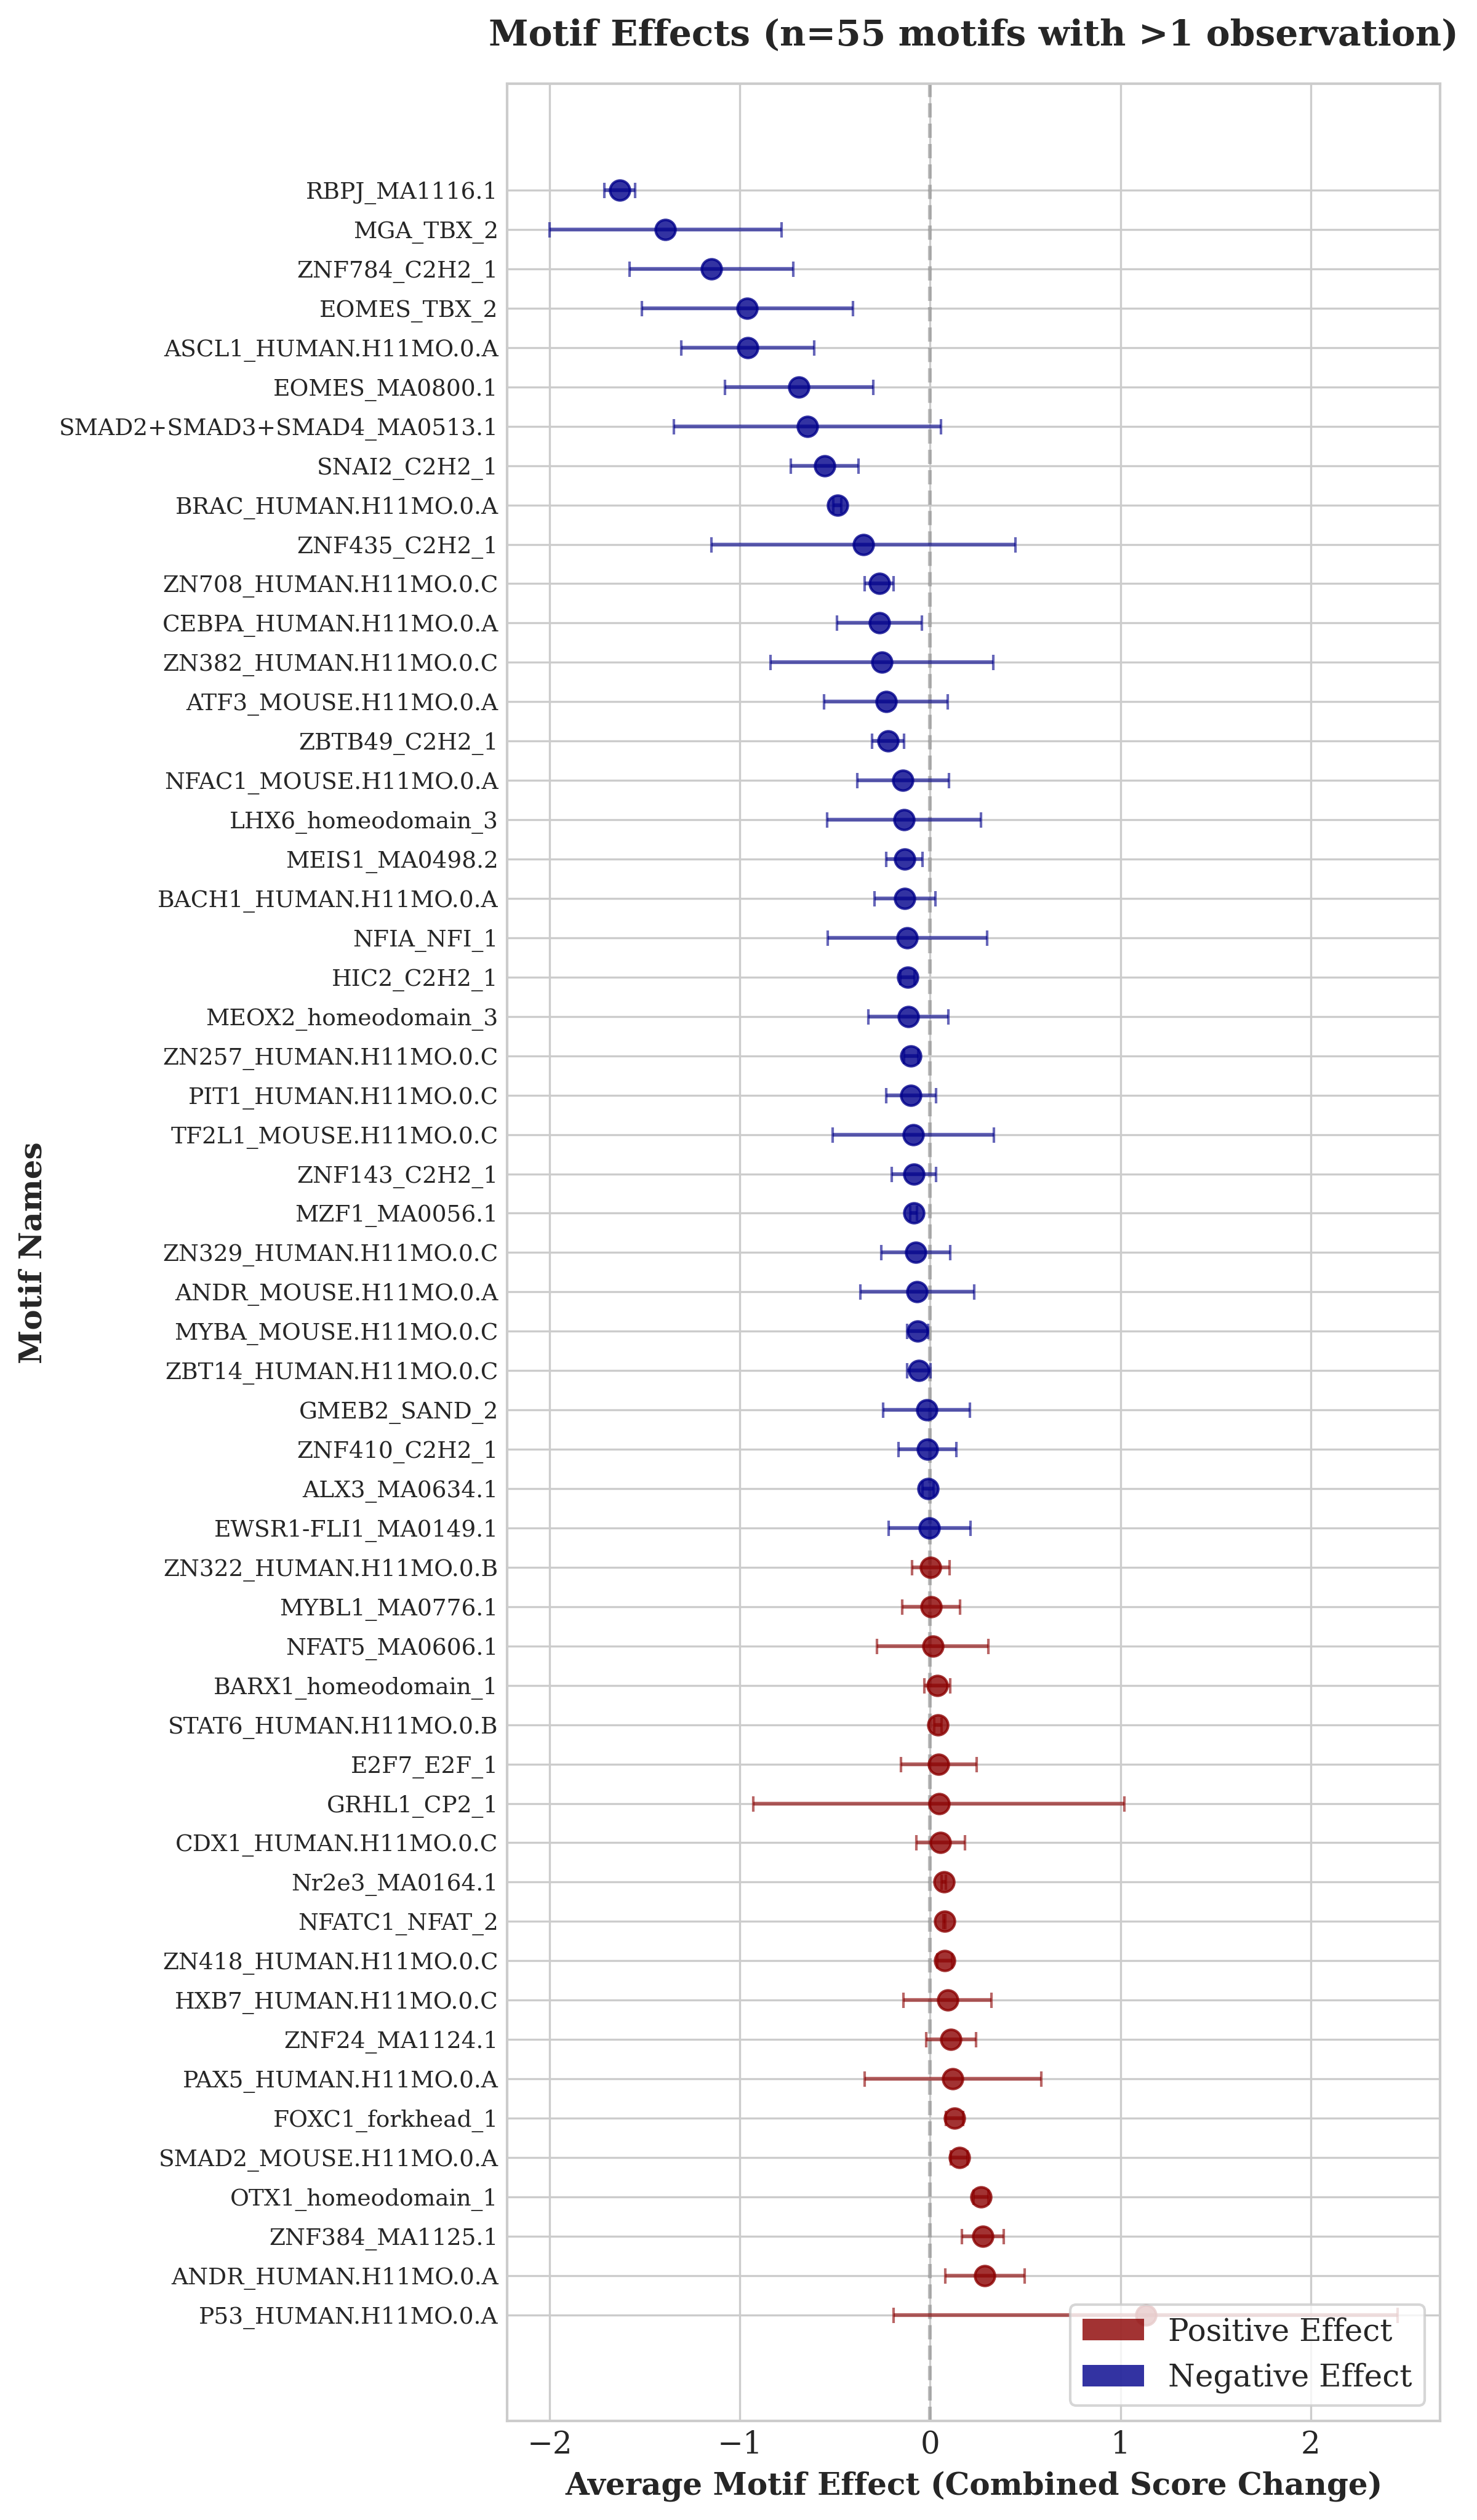

In [49]:
# Set style
plt.style.use('seaborn-v0_8-whitegrid')
rcParams['font.family'] = 'serif'
rcParams['font.size'] = 10
rcParams['axes.labelsize'] = 12
rcParams['axes.titlesize'] = 14

# Create the plot with appropriate size
fig, ax = plt.subplots(figsize=(8, max(6, len(sorted_motif_names) * 0.25)), dpi=300)

# Create y positions
y_pos = np.arange(len(sorted_motif_names))

# Plot the data
for i, (motif, values) in enumerate(zip(sorted_motif_names, sorted_motif_values)):
    # Calculate statistics
    mean_val = np.mean(values)
    std_val = np.std(values)
    
    # Plot mean as a dot
    color = 'darkred' if mean_val > 0 else 'darkblue'
    ax.scatter(mean_val, i, s=60, color=color, alpha=0.8, zorder=3)
    
    # Plot error bars (standard deviation)
    ax.errorbar(mean_val, i, xerr=std_val, fmt='none', 
                color=color, alpha=0.6, capsize=3, capthick=1)

# Customize the plot
ax.set_yticks(y_pos)
ax.set_yticklabels(sorted_motif_names, fontsize=9)
ax.set_xlabel('Average Motif Effect (Combined Score Change)', fontweight='bold')
ax.set_ylabel('Motif Names', fontweight='bold')
ax.set_title(f'Motif Effects (n={len(sorted_motif_names)} motifs with >1 observation)', 
             fontweight='bold', pad=15)

# Add vertical line at x=0 for reference
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5, zorder=1)

# Add color coding legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='darkred', alpha=0.8, label='Positive Effect'),
    Patch(facecolor='darkblue', alpha=0.8, label='Negative Effect')
]
ax.legend(handles=legend_elements, loc='lower right', frameon=True)

# Improve layout
plt.tight_layout()

# Save the plot
plt.savefig('filtered_motif_effects.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.savefig('filtered_motif_effects.png', format='png', dpi=300, bbox_inches='tight')

plt.show()

Total motifs: 151
Positive effects: 65 (43.0%)
Negative effects: 86 (57.0%)
Zero effects: 0 (0.0%)


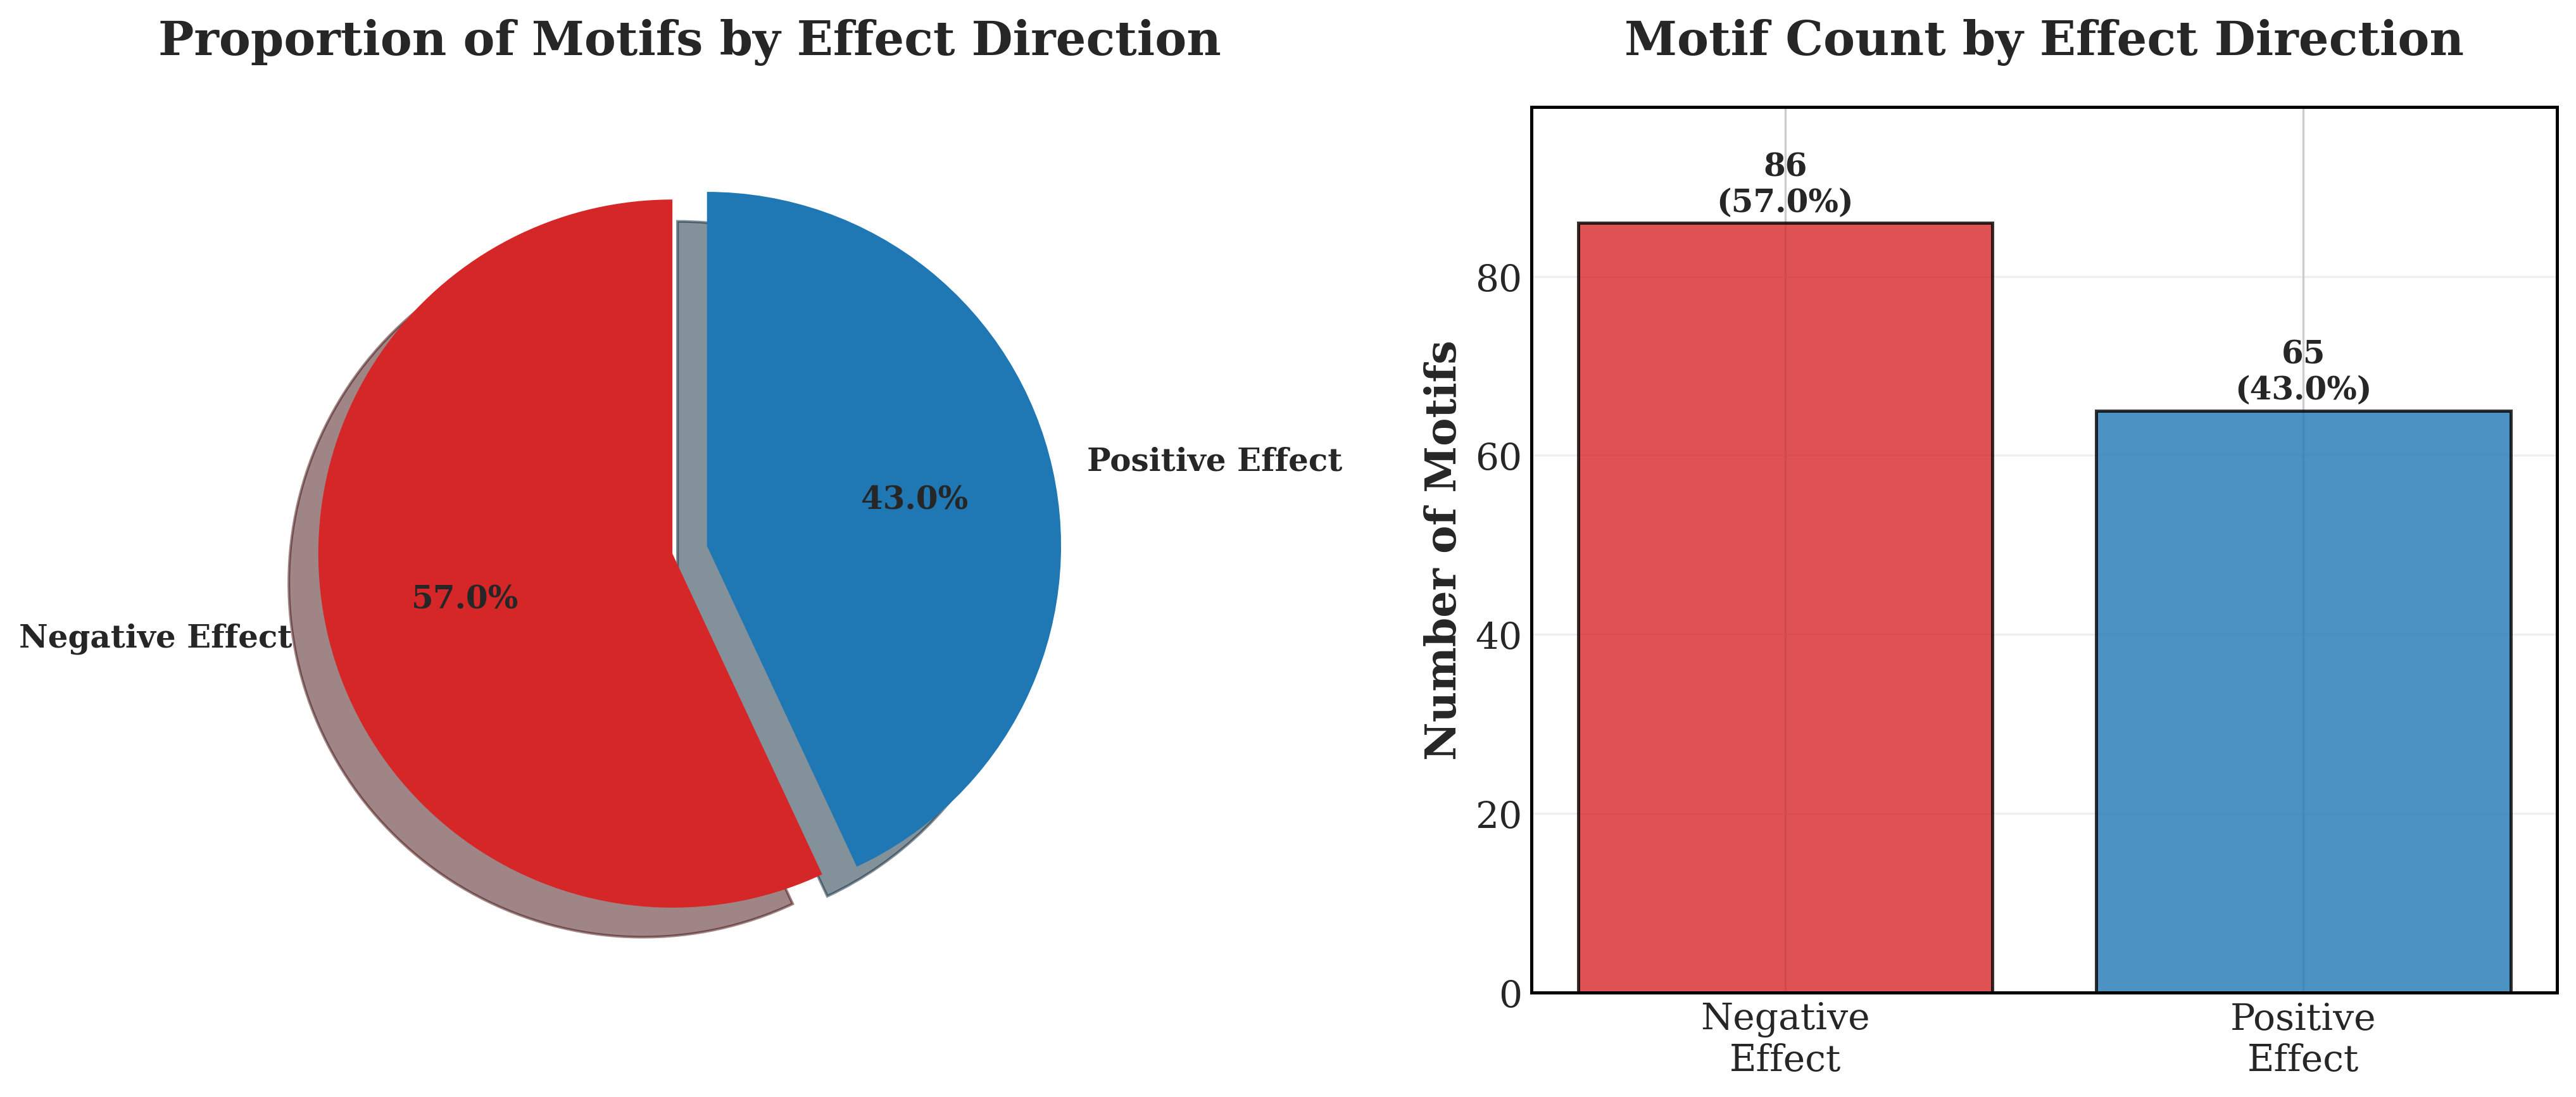


Summary Statistics:
Mean effect size: -0.0917
Median effect size: -0.0411
Standard deviation: 0.3840
Range: [-1.6321, 1.3305]


In [50]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rcParams
import seaborn as sns

# Set publication-ready style
plt.style.use('seaborn-v0_8-whitegrid')
rcParams['font.family'] = 'serif'
rcParams['font.size'] = 14
rcParams['axes.labelsize'] = 16
rcParams['axes.titlesize'] = 18
rcParams['xtick.labelsize'] = 14
rcParams['ytick.labelsize'] = 14
rcParams['legend.fontsize'] = 14

# Calculate proportions
effect_sizes = list(motif_effects_sum.values())
positive_effects = sum(1 for x in effect_sizes if x > 0)
negative_effects = sum(1 for x in effect_sizes if x < 0)
zero_effects = sum(1 for x in effect_sizes if x == 0)

total_motifs = len(effect_sizes)
positive_prop = positive_effects / total_motifs
negative_prop = negative_effects / total_motifs
zero_prop = zero_effects / total_motifs

print(f"Total motifs: {total_motifs}")
print(f"Positive effects: {positive_effects} ({positive_prop:.1%})")
print(f"Negative effects: {negative_effects} ({negative_prop:.1%})")
print(f"Zero effects: {zero_effects} ({zero_prop:.1%})")

# Create the plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# Plot 1: Pie chart
colors = ['#d62728', '#1f77b4', '#7f7f7f']  # Red for negative, blue for positive, gray for zero
labels = ['Negative Effect', 'Positive Effect', 'Zero Effect']
sizes = [negative_effects, positive_effects, zero_effects]
explode = (0.05, 0.05, 0.05)  # slightly separate all slices

# Only include non-zero categories
non_zero_sizes = [s for s in sizes if s > 0]
non_zero_labels = [labels[i] for i, s in enumerate(sizes) if s > 0]
non_zero_colors = [colors[i] for i, s in enumerate(sizes) if s > 0]
non_zero_explode = [explode[i] for i, s in enumerate(sizes) if s > 0]

wedges, texts, autotexts = ax1.pie(non_zero_sizes, 
                                  labels=non_zero_labels, 
                                  colors=non_zero_colors,
                                  autopct='%1.1f%%',
                                  explode=non_zero_explode,
                                  shadow=True,
                                  startangle=90,
                                  textprops={'fontsize': 12, 'fontweight': 'bold'})

ax1.set_title('Proportion of Motifs by Effect Direction', fontweight='bold', pad=20)

# Plot 2: Bar chart
categories = []
counts = []
colors_bar = []

if negative_effects > 0:
    categories.append('Negative\nEffect')
    counts.append(negative_effects)
    colors_bar.append('#d62728')

if positive_effects > 0:
    categories.append('Positive\nEffect')
    counts.append(positive_effects)
    colors_bar.append('#1f77b4')

if zero_effects > 0:
    categories.append('Zero\nEffect')
    counts.append(zero_effects)
    colors_bar.append('#7f7f7f')

bars = ax2.bar(categories, counts, color=colors_bar, alpha=0.8, edgecolor='black', linewidth=1.2)

# Add count labels on bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.5,
             f'{count}\n({count/total_motifs:.1%})',
             ha='center', va='bottom', fontweight='bold', fontsize=12)

ax2.set_ylabel('Number of Motifs', fontweight='bold')
ax2.set_title('Motif Count by Effect Direction', fontweight='bold', pad=20)
ax2.set_ylim(0, max(counts) * 1.15)

# Add grid for better readability
ax2.grid(True, alpha=0.3, axis='y')

# Style the spines
for ax in [ax1, ax2]:
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1.2)

plt.tight_layout()

# Save the plots
plt.savefig('motif_effect_proportions.pdf', format='pdf', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('motif_effect_proportions.png', format='png', dpi=300, bbox_inches='tight', facecolor='white')

plt.show()

# Print summary statistics
print(f"\nSummary Statistics:")
print(f"Mean effect size: {np.mean(effect_sizes):.4f}")
print(f"Median effect size: {np.median(effect_sizes):.4f}")
print(f"Standard deviation: {np.std(effect_sizes):.4f}")
print(f"Range: [{np.min(effect_sizes):.4f}, {np.max(effect_sizes):.4f}]")

In [51]:
class BelugaWrapper(torch.nn.Module):

    def __init__(self, beluga, task_idx):
        super().__init__()
        self.model = beluga
        self.task_idx = task_idx
    
    def forward(self, X):
        return self.model(X)[:,self.task_idx][:,None]

# --task_id_down 1367 --task_id_up 1385

mdl = Beluga()
mdl.load_state_dict(torch.load('../deepSEA_negatives/deepsea.beluga.pth')) 

wrapper_task_up = BelugaWrapper(mdl, 1385)
wrapper_task_down = BelugaWrapper(mdl, 1367)

In [53]:
# next we need to get all the inserted motifs and their names
annots = pd.read_excel("../ap1_counting/data/motif_annotations.xlsx",engine='openpyxl')
archetypes = pd.read_csv("../ap1_counting/data/motifs.tsv", sep="\t")
all_motifs = archetypes[archetypes["Motif"].isin(annots["Seed_motif"])][["Cluster_ID","Consensus"]]

consensus_to_cluster = all_motifs.set_index("Consensus")["Cluster_ID"].to_dict()

name_to_seq = {}
seq_to_name = {}

for k,v in consensus_to_cluster.items():
    name = annots[annots.Cluster_ID == v]["Name"].values[0]

    name_to_seq[name] = k
    seq_to_name[k] = name

In [59]:
id = 64
position = 1003

seq_name = f"edited_seq_0_{id}.pkl"

file_name = f"./7.14.designs/results_0_{id}.pkl"

with open(file_name, "rb") as f:
    results = pickle.load(f)

results["motif_names"] = [seq_to_name[i] for i in results["sequence_added"]]

# read in seq_name
with open(f"./7.14.designs/{seq_name}", "rb") as f:
    seq = pickle.load(f)

characters(torch.tensor(seq.squeeze())).find("GAGTCCAAAGTCCA")

-1

In [61]:
X_down = deep_lift_shap(wrapper_task_down, torch.tensor(seq).type(torch.float32), verbose=True)
X_up = deep_lift_shap(wrapper_task_up, torch.tensor(seq).type(torch.float32), verbose=True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 189.41it/s]


[Text(-5.0, 0, ''),
 Text(0.0, 0, ''),
 Text(5.0, 0, ''),
 Text(10.0, 0, ''),
 Text(15.0, 0, ''),
 Text(20.0, 0, ''),
 Text(25.0, 0, ''),
 Text(30.0, 0, ''),
 Text(35.0, 0, ''),
 Text(40.0, 0, '')]

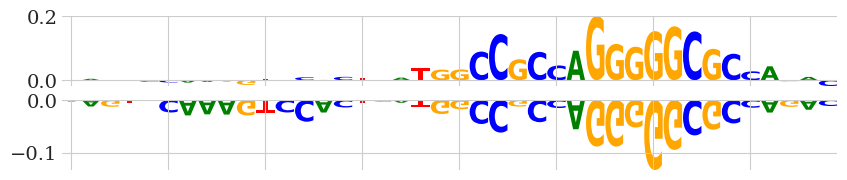

In [64]:
from matplotlib import pyplot as plt
# import seaborn; seaborn.set_style('whitegrid')
from tangermeme.plot import plot_logo
start = position
end = position + 40

plt.figure(figsize=(10, 2))
ax = plt.subplot(212)
plot_logo(X_down[0, :, start:end], ax=ax)
ax.set_xticklabels([])

ax = plt.subplot(211)
plot_logo(X_up[0, :, start:end], ax=ax)
ax.set_xticklabels([])

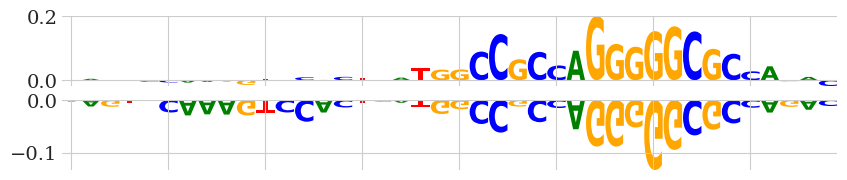

In [65]:
from matplotlib import pyplot as plt
# import seaborn; seaborn.set_style('whitegrid')
from tangermeme.plot import plot_logo
start = position
end = position + 40

plt.figure(figsize=(10, 2))
ax = plt.subplot(212)
plot_logo(X_down[0, :, start:end], ax=ax)
ax.set_xticklabels([])

ax = plt.subplot(211)
plot_logo(X_up[0, :, start:end], ax=ax)
ax.set_xticklabels([])

# Save as PDF vector graphic
plt.savefig('logo_plot.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()  # Optional: still display the plot

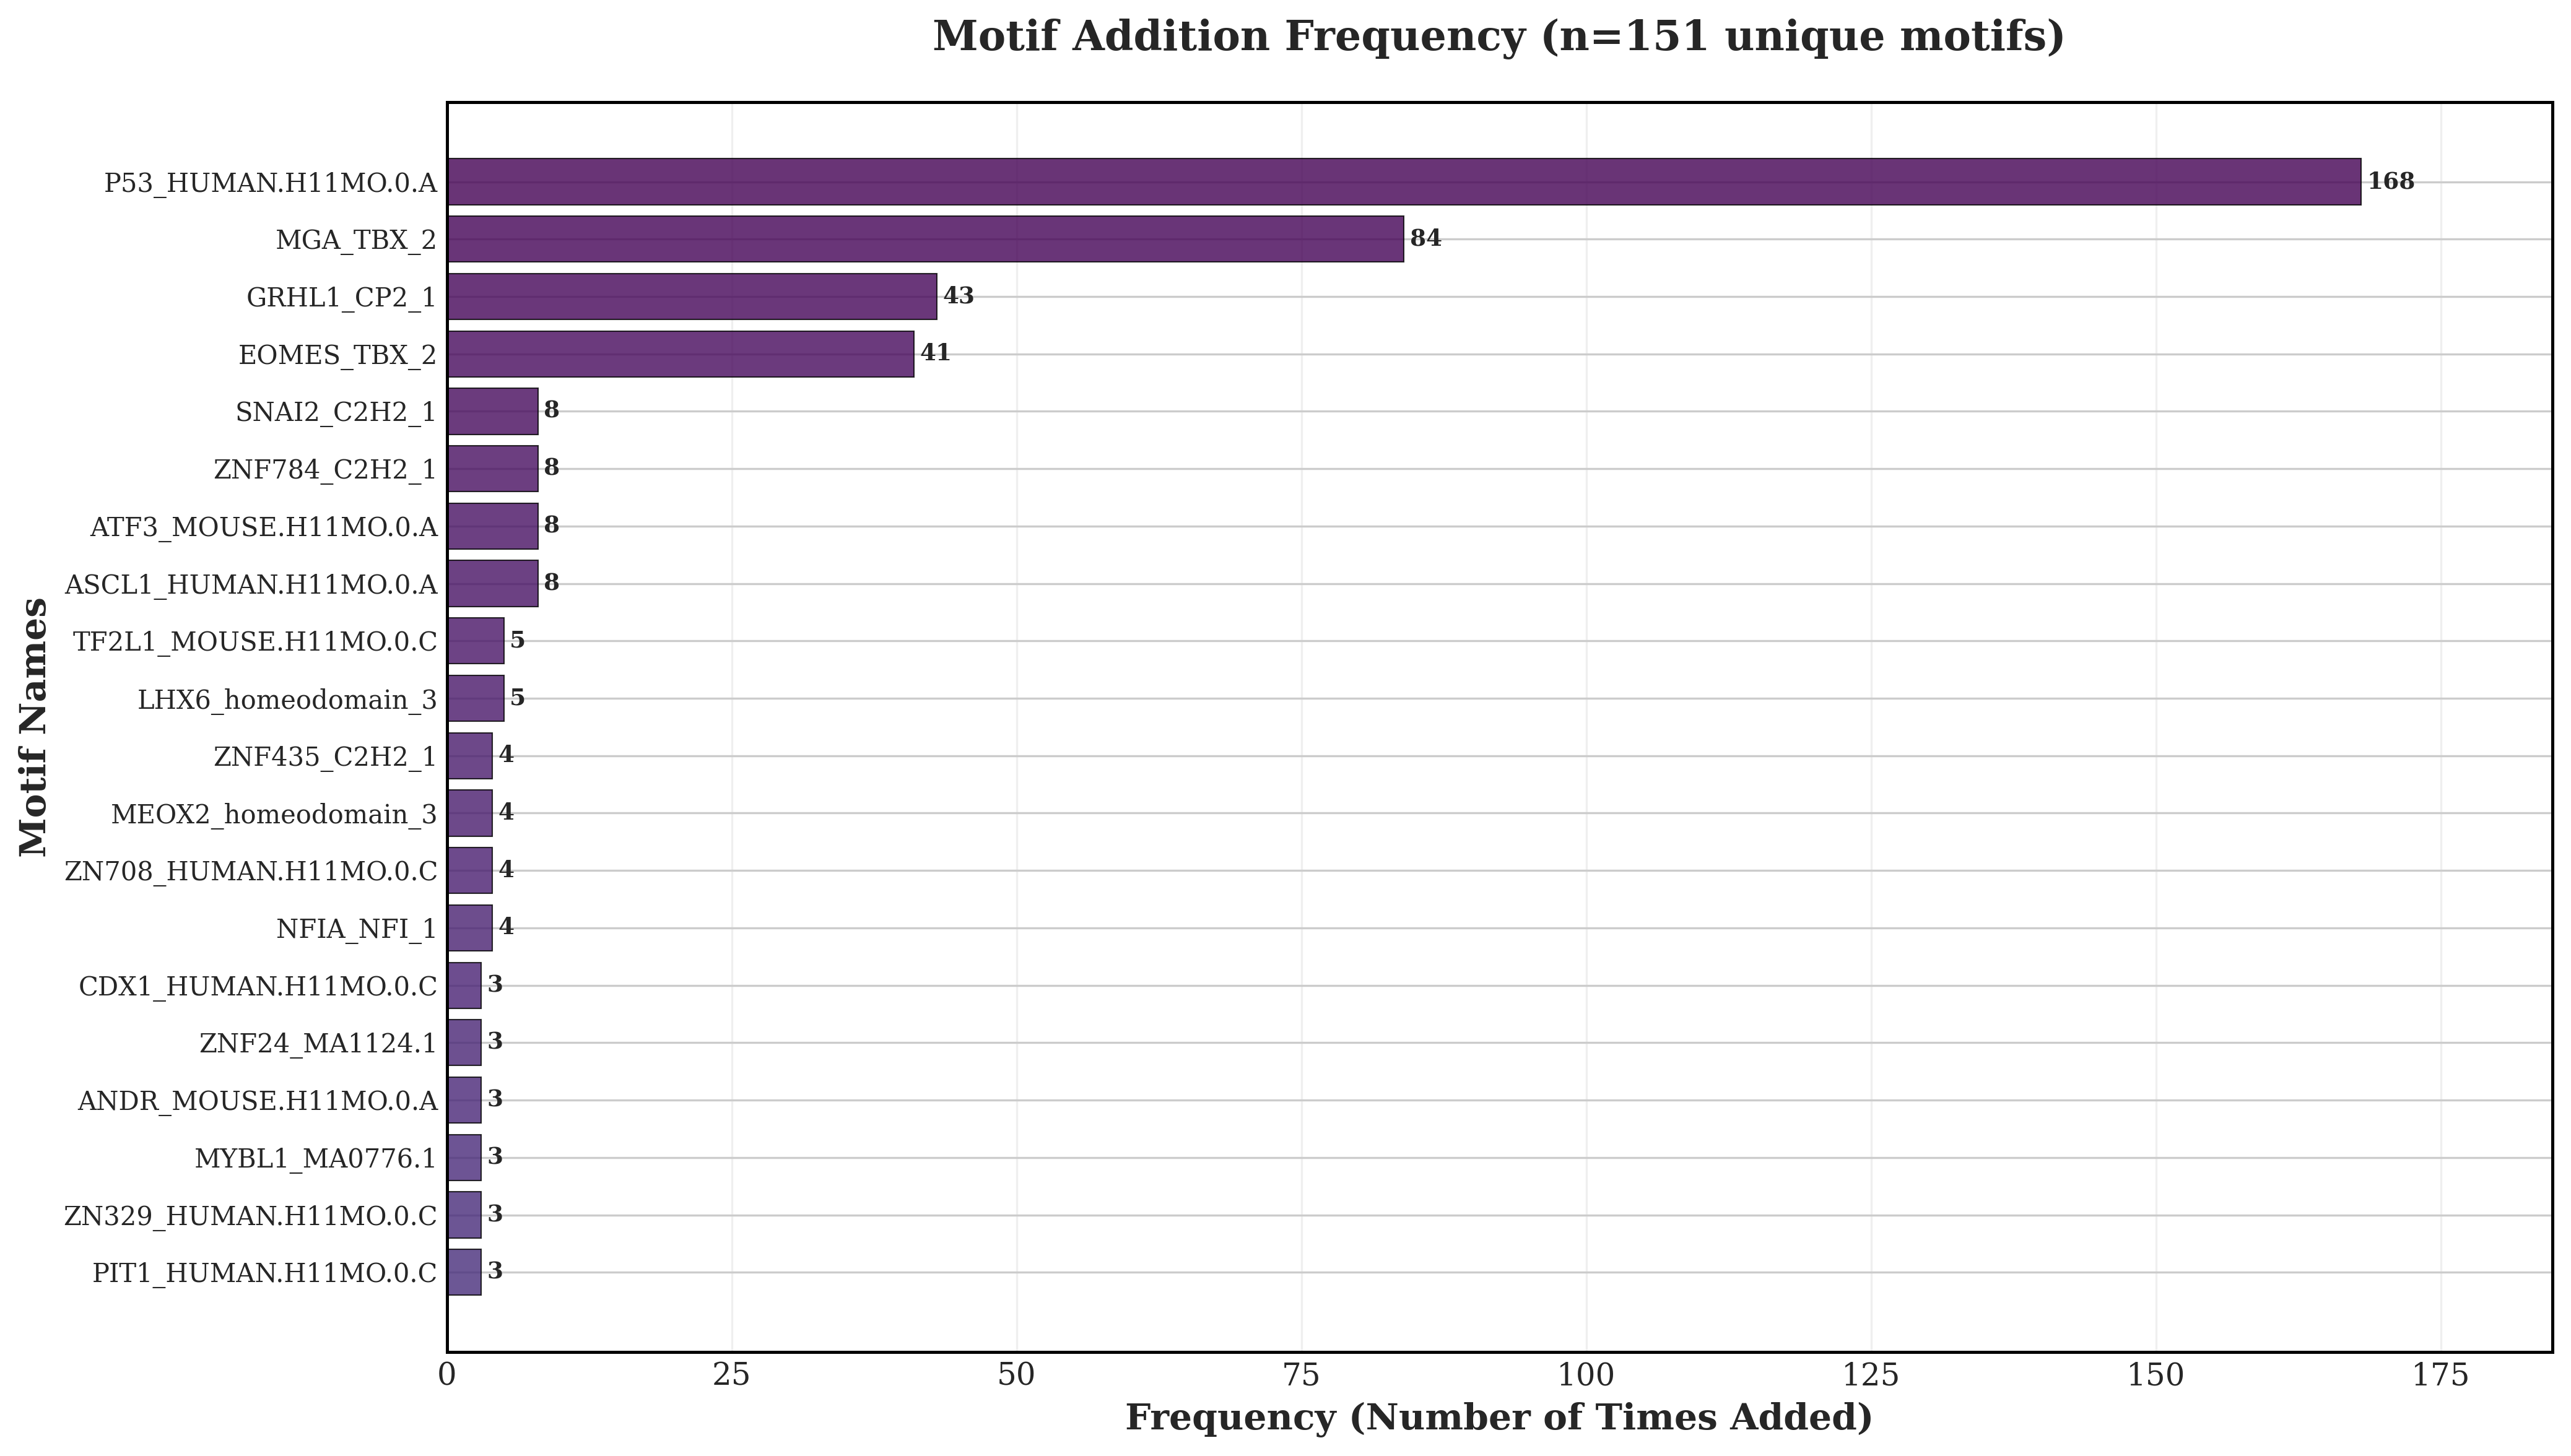

Total unique motifs: 151
Total motif additions: 582
Mean frequency: 3.85
Median frequency: 1.00

Top 10 most frequent motifs:
 1. P53_HUMAN.H11MO.0.A: 168
 2. MGA_TBX_2: 84
 3. GRHL1_CP2_1: 43
 4. EOMES_TBX_2: 41
 5. SNAI2_C2H2_1: 8
 6. ZNF784_C2H2_1: 8
 7. ATF3_MOUSE.H11MO.0.A: 8
 8. ASCL1_HUMAN.H11MO.0.A: 8
 9. TF2L1_MOUSE.H11MO.0.C: 5
10. LHX6_homeodomain_3: 5


In [68]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rcParams
from collections import Counter

# Set publication-ready style
plt.style.use('seaborn-v0_8-whitegrid')
rcParams['font.family'] = 'serif'
rcParams['font.size'] = 12
rcParams['axes.labelsize'] = 14
rcParams['axes.titlesize'] = 16
rcParams['xtick.labelsize'] = 12
rcParams['ytick.labelsize'] = 12
rcParams['legend.fontsize'] = 12

# Calculate motif frequencies (number of times each motif was added)
motif_frequencies = {motif: len(effects) for motif, effects in motif_effects.items()}

# Sort motifs by frequency (most frequent first)
sorted_motifs = sorted(motif_frequencies.items(), key=lambda x: x[1], reverse=True)

# Extract motif names and frequencies
motif_names = [motif for motif, freq in sorted_motifs]
frequencies = [freq for motif, freq in sorted_motifs]

# Create the plot
fig, ax = plt.subplots(figsize=(14, 8), dpi=300)

# Create color map based on frequency
colors = plt.cm.viridis(np.linspace(0, 1, len(frequencies)))

# Create horizontal bar plot
bars = ax.barh(range(len(motif_names))[:20], frequencies[:20], color=colors[:20], 
               alpha=0.8, edgecolor='black', linewidth=0.5)

# Customize the plot
ax.set_yticks(range(len(motif_names))[:20])
ax.set_yticklabels(motif_names[:20], fontsize=10)
ax.set_xlabel('Frequency (Number of Times Added)', fontweight='bold')
ax.set_ylabel('Motif Names', fontweight='bold')
ax.set_title(f'Motif Addition Frequency (n={len(motif_names)} unique motifs)', 
             fontweight='bold', pad=20)

# Add frequency labels on bars
for i, (bar, freq) in enumerate(zip(bars[:20], frequencies[:20])):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, 
            str(freq), ha='left', va='center', fontweight='bold', fontsize=9)

# Add grid for better readability
ax.grid(True, alpha=0.3, axis='x')

# Invert y-axis to show highest frequency at top
ax.invert_yaxis()

# Set x-axis limits with some padding
ax.set_xlim(0, max(frequencies[:20]) * 1.1)

# Style the spines
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)

plt.tight_layout()

# Save as PDF vector graphic
plt.savefig('motif_frequency_plot.pdf', format='pdf', dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')

# Also save as PNG
plt.savefig('motif_frequency_plot.png', format='png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')

plt.show()

# Print summary statistics
print(f"Total unique motifs: {len(motif_frequencies)}")
print(f"Total motif additions: {sum(frequencies)}")
print(f"Mean frequency: {np.mean(frequencies):.2f}")
print(f"Median frequency: {np.median(frequencies):.2f}")
print(f"\nTop 10 most frequent motifs:")
for i, (motif, freq) in enumerate(sorted_motifs[:10]):
    print(f"{i+1:2d}. {motif}: {freq}")

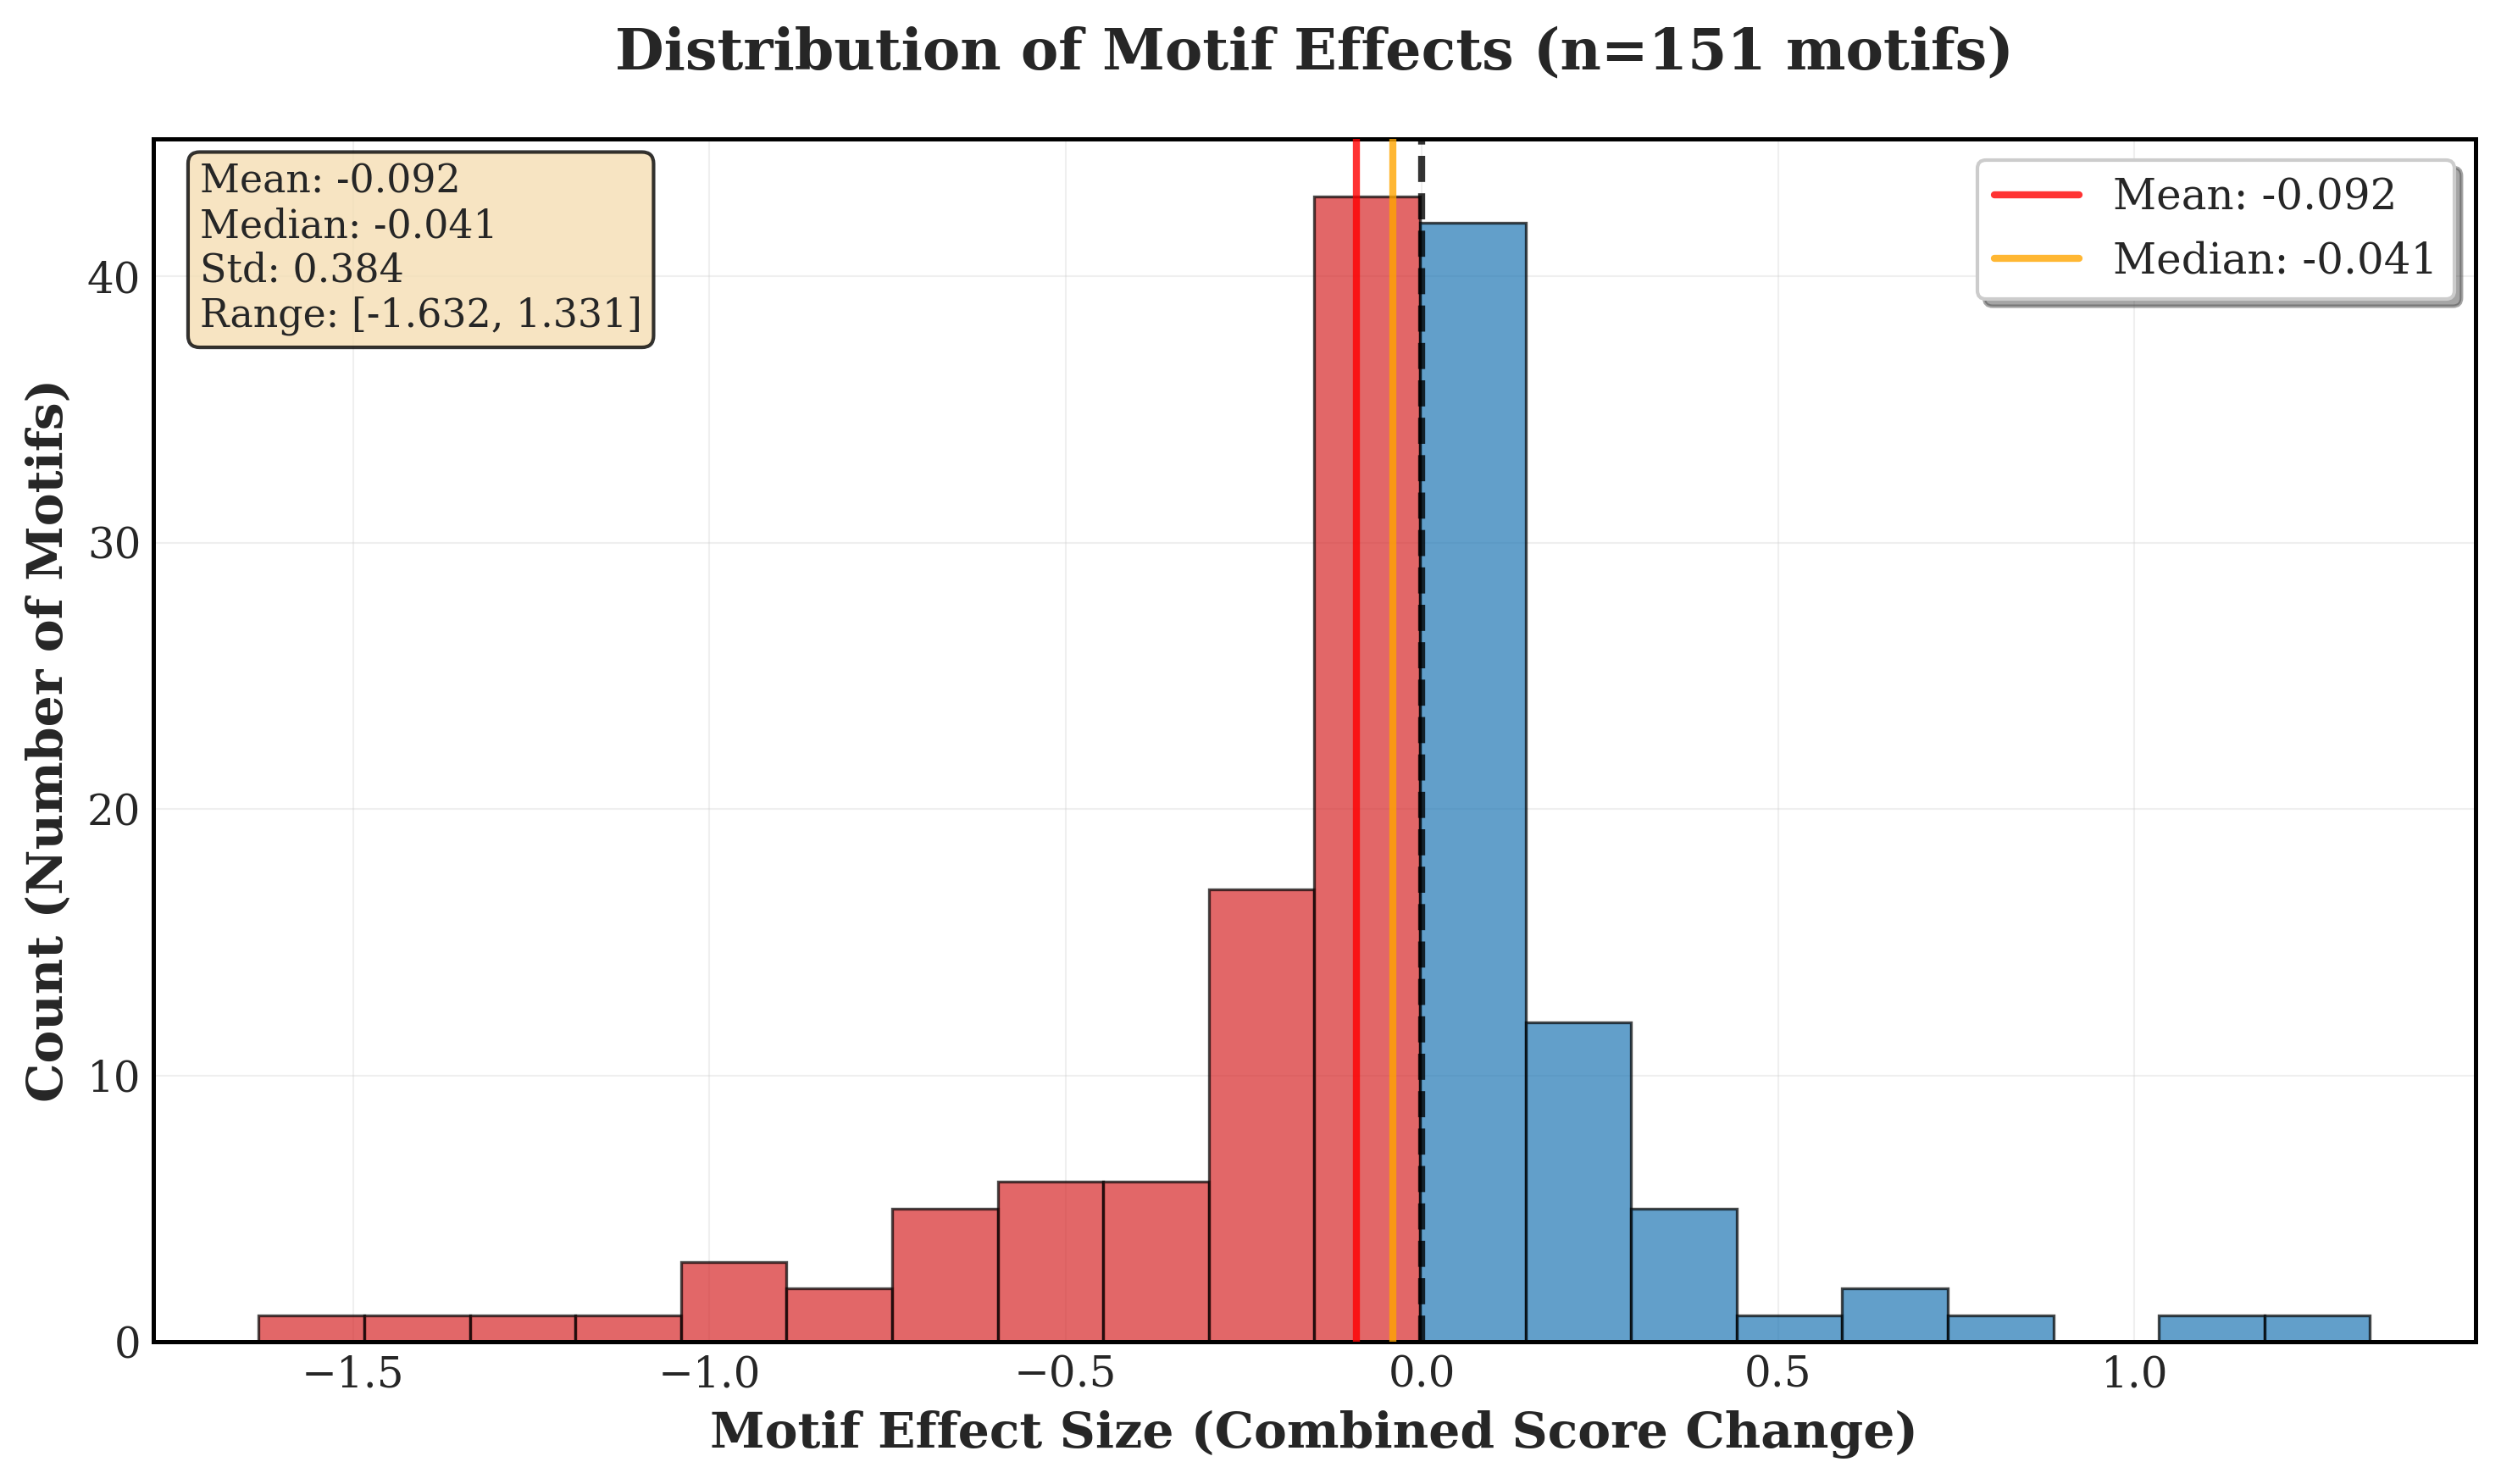

Distribution Statistics:
Total motifs: 151
Mean effect: -0.0917
Median effect: -0.0411
Standard deviation: 0.3840
Skewness: -0.6023
Range: [-1.6321, 1.3305]
Positive effects: 65 (43.0%)
Negative effects: 86 (57.0%)


In [69]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rcParams
import seaborn as sns

# Set publication-ready style
plt.style.use('seaborn-v0_8-whitegrid')
rcParams['font.family'] = 'serif'
rcParams['font.size'] = 12
rcParams['axes.labelsize'] = 14
rcParams['axes.titlesize'] = 16
rcParams['xtick.labelsize'] = 12
rcParams['ytick.labelsize'] = 12
rcParams['legend.fontsize'] = 12

# Extract effect sizes
effect_sizes = list(motif_effects_sum.values())

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

# Create histogram with optimal number of bins
n_bins = max(20, int(np.sqrt(len(effect_sizes))))  # Use square root rule with minimum of 20
counts, bins, patches = ax.hist(effect_sizes, bins=n_bins, alpha=0.7, 
                               edgecolor='black', linewidth=0.8, color='steelblue')

# Color bars based on effect direction
for i, (patch, bin_left, bin_right) in enumerate(zip(patches, bins[:-1], bins[1:])):
    bin_center = (bin_left + bin_right) / 2
    if bin_center < 0:
        patch.set_facecolor('#d62728')  # Red for negative effects
        patch.set_alpha(0.7)
    elif bin_center > 0:
        patch.set_facecolor('#1f77b4')  # Blue for positive effects
        patch.set_alpha(0.7)
    else:
        patch.set_facecolor('#7f7f7f')  # Gray for zero effects
        patch.set_alpha(0.7)

# Add vertical line at x=0 for reference
ax.axvline(x=0, color='black', linestyle='--', linewidth=2, alpha=0.8, zorder=10)

# Add mean and median lines
mean_effect = np.mean(effect_sizes)
median_effect = np.median(effect_sizes)

ax.axvline(x=mean_effect, color='red', linestyle='-', linewidth=2, 
           alpha=0.8, label=f'Mean: {mean_effect:.3f}', zorder=10)
ax.axvline(x=median_effect, color='orange', linestyle='-', linewidth=2, 
           alpha=0.8, label=f'Median: {median_effect:.3f}', zorder=10)

# Customize the plot
ax.set_xlabel('Motif Effect Size (Combined Score Change)', fontweight='bold')
ax.set_ylabel('Count (Number of Motifs)', fontweight='bold')
ax.set_title(f'Distribution of Motif Effects (n={len(effect_sizes)} motifs)', 
             fontweight='bold', pad=20)

# Add legend
ax.legend(loc='upper right', frameon=True, fancybox=True, shadow=True)

# Add text box with statistics
stats_text = f'Mean: {mean_effect:.3f}\n' \
             f'Median: {median_effect:.3f}\n' \
             f'Std: {np.std(effect_sizes):.3f}\n' \
             f'Range: [{np.min(effect_sizes):.3f}, {np.max(effect_sizes):.3f}]'

ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Add grid for better readability
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Style the spines
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)

# Adjust layout
plt.tight_layout()

# Save as PDF vector graphic
plt.savefig('motif_effects_histogram.pdf', format='pdf', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')

# Also save as PNG
plt.savefig('motif_effects_histogram.png', format='png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')

plt.show()

# Print additional statistics
print(f"Distribution Statistics:")
print(f"Total motifs: {len(effect_sizes)}")
print(f"Mean effect: {mean_effect:.4f}")
print(f"Median effect: {median_effect:.4f}")
print(f"Standard deviation: {np.std(effect_sizes):.4f}")
print(f"Skewness: {((np.array(effect_sizes) - mean_effect) ** 3).mean() / (np.std(effect_sizes) ** 3):.4f}")
print(f"Range: [{np.min(effect_sizes):.4f}, {np.max(effect_sizes):.4f}]")
print(f"Positive effects: {sum(1 for x in effect_sizes if x > 0)} ({sum(1 for x in effect_sizes if x > 0)/len(effect_sizes):.1%})")
print(f"Negative effects: {sum(1 for x in effect_sizes if x < 0)} ({sum(1 for x in effect_sizes if x < 0)/len(effect_sizes):.1%})")